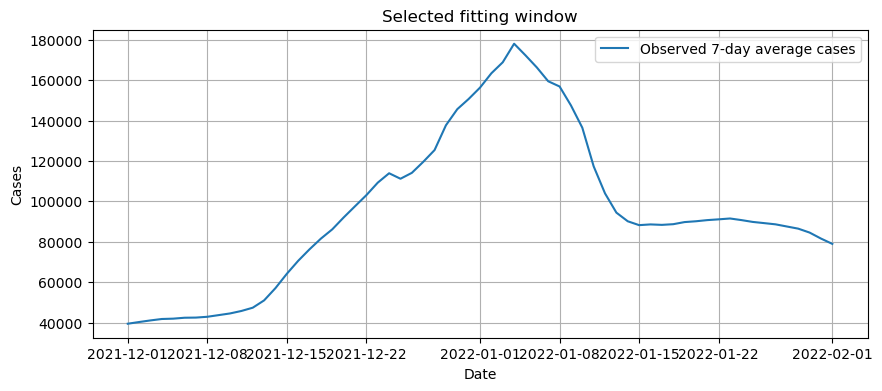

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize

# load data
df = pd.read_csv("../data/uk_final.csv")
df["date"] = pd.to_datetime(df["date"])

# choose fitting window
df_fit = df[(df["date"] >= "2021-12-01") & (df["date"] <= "2022-02-01")].copy()
df_fit = df_fit.reset_index(drop=True)

# fitting target
data = df_fit["cases_7d"].values
t = np.arange(len(data))

# population
N = 67_000_000

# initial values
I0 = float(data[0])
R0 = 0.0
S0 = N - I0 - R0

# quick check
plt.figure(figsize=(10, 4))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases")
plt.title("Selected fitting window")
plt.xlabel("Date")
plt.ylabel("Cases")
plt.legend()
plt.grid()
plt.show()

In [4]:
def sir_piecewise_beta(t_now, y, beta, gamma, N):
    S, I, R = y
    dSdt = -beta * S * I / N
    dIdt = beta * S * I / N - gamma * I
    dRdt = gamma * I
    return [dSdt, dIdt, dRdt]

def simulate_piecewise_sir(beta1, beta2, gamma, t_switch, S0, I0, R0, N, t_eval):
    # split the time grid into two parts
    t_eval_1 = t_eval[t_eval < t_switch]
    t_eval_2 = t_eval[t_eval >= t_switch]

    # first segment
    if len(t_eval_1) > 0:
        sol1 = solve_ivp(
            fun=lambda t_now, y: sir_piecewise_beta(t_now, y, beta1, gamma, N),
            t_span=(t_eval_1[0], t_eval_1[-1]),
            y0=[S0, I0, R0],
            t_eval=t_eval_1,
            method="RK45"
        )
        S1, I1, R1 = sol1.y
        y_switch = [S1[-1], I1[-1], R1[-1]]
    else:
        S1, I1, R1 = np.array([]), np.array([]), np.array([])
        y_switch = [S0, I0, R0]

    # second segment
    if len(t_eval_2) > 0:
        sol2 = solve_ivp(
            fun=lambda t_now, y: sir_piecewise_beta(t_now, y, beta2, gamma, N),
            t_span=(t_eval_2[0], t_eval_2[-1]),
            y0=y_switch,
            t_eval=t_eval_2,
            method="RK45"
        )
        S2, I2, R2 = sol2.y
    else:
        S2, I2, R2 = np.array([]), np.array([]), np.array([])

    # combine
    S = np.concatenate([S1, S2])
    I = np.concatenate([I1, I2])
    R = np.concatenate([R1, R2])

    return S, I, R

def fit_for_fixed_switch(t_switch):
    def loss_fn(params):
        beta1, beta2, gamma = params

        if beta1 <= 0 or beta2 <= 0 or gamma <= 0:
            return 1e20

        S, I, R = simulate_piecewise_sir(beta1, beta2, gamma, t_switch, S0, I0, R0, N, t)

        # extra safety check
        if len(I) != len(data):
            return 1e20

        return np.mean((I - data) ** 2)

    result = minimize(
        loss_fn,
        x0=[0.5, 0.15, 0.1],
        bounds=[(1e-6, 2.0), (1e-6, 2.0), (1e-6, 1.0)],
        method="L-BFGS-B"
    )

    beta1_fit, beta2_fit, gamma_fit = result.x
    S_fit, I_fit, R_fit = simulate_piecewise_sir(beta1_fit, beta2_fit, gamma_fit, t_switch, S0, I0, R0, N, t)
    mse = np.mean((I_fit - data) ** 2)

    return {
        "t_switch": t_switch,
        "beta1": beta1_fit,
        "beta2": beta2_fit,
        "gamma": gamma_fit,
        "mse": mse,
        "S_fit": S_fit,
        "I_fit": I_fit,
        "R_fit": R_fit
    }

candidate_switches = range(7, len(t) - 7)

all_results = []
for ts in candidate_switches:
    res = fit_for_fixed_switch(ts)
    all_results.append(res)

best_result = min(all_results, key=lambda x: x["mse"])

t_switch_best = best_result["t_switch"]
beta1_best = best_result["beta1"]
beta2_best = best_result["beta2"]
gamma_best = best_result["gamma"]
S_fit = best_result["S_fit"]
I_fit = best_result["I_fit"]
R_fit = best_result["R_fit"]

mse = best_result["mse"]
rmse = np.sqrt(mse)
switch_date = df_fit["date"].iloc[t_switch_best]

print("Best switch day index =", t_switch_best)
print("Best switch date =", switch_date.date())
print("beta1 =", beta1_best)
print("beta2 =", beta2_best)
print("gamma =", gamma_best)
print("R0 before switch =", beta1_best / gamma_best)
print("R0 after switch  =", beta2_best / gamma_best)
print("MSE =", mse)
print("RMSE =", rmse)

Best switch day index = 34
Best switch date = 2022-01-04
beta1 = 0.07725468774076744
beta2 = 1e-06
gamma = 0.03369988841219958
R0 before switch = 2.2924315592926634
R0 after switch  = 2.967368876028662e-05
MSE = 130652076.15481286
RMSE = 11430.313913222719


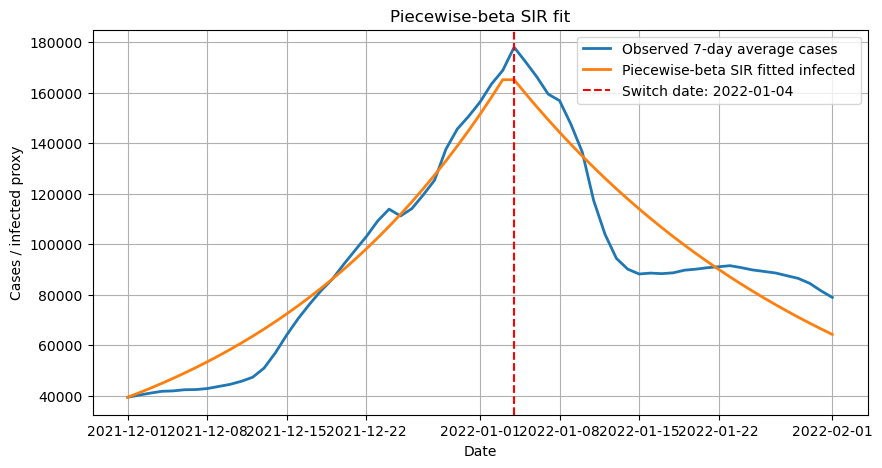

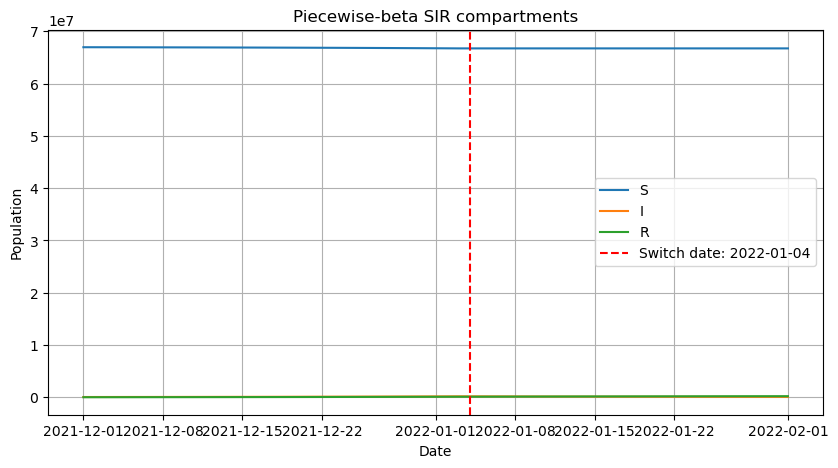

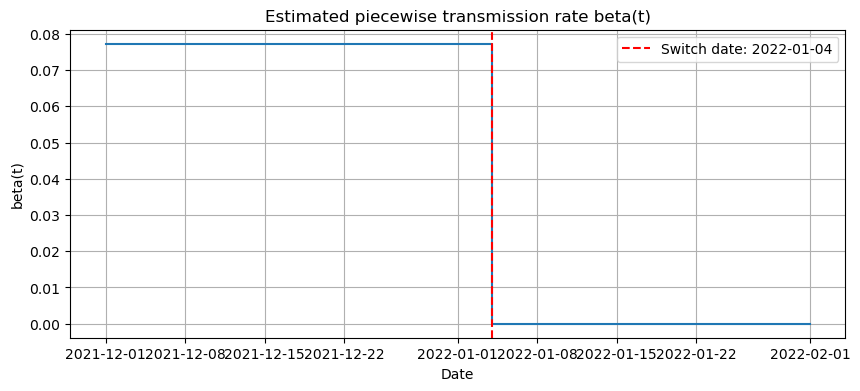

           quantity             value
0  switch_day_index                34
1       switch_date        2022-01-04
2             beta1          0.077255
3             beta2          0.000001
4             gamma            0.0337
5         R0_before          2.292432
6          R0_after           0.00003
7               MSE  130652076.154813
8              RMSE      11430.313913


In [5]:
# fitted curve
plt.figure(figsize=(10, 5))
plt.plot(df_fit["date"], data, label="Observed 7-day average cases", linewidth=2)
plt.plot(df_fit["date"], I_fit, label="Piecewise-beta SIR fitted infected", linewidth=2)
plt.axvline(switch_date, color="red", linestyle="--", label=f"Switch date: {switch_date.date()}")
plt.title("Piecewise-beta SIR fit")
plt.xlabel("Date")
plt.ylabel("Cases / infected proxy")
plt.legend()
plt.grid()
plt.show()

# compartments
plt.figure(figsize=(10, 5))
plt.plot(df_fit["date"], S_fit, label="S")
plt.plot(df_fit["date"], I_fit, label="I")
plt.plot(df_fit["date"], R_fit, label="R")
plt.axvline(switch_date, color="red", linestyle="--", label=f"Switch date: {switch_date.date()}")
plt.title("Piecewise-beta SIR compartments")
plt.xlabel("Date")
plt.ylabel("Population")
plt.legend()
plt.grid()
plt.show()

# beta path
beta_path = np.array([beta1_best if ti < t_switch_best else beta2_best for ti in t])

plt.figure(figsize=(10, 4))
plt.step(df_fit["date"], beta_path, where="post")
plt.axvline(switch_date, color="red", linestyle="--", label=f"Switch date: {switch_date.date()}")
plt.title("Estimated piecewise transmission rate beta(t)")
plt.xlabel("Date")
plt.ylabel("beta(t)")
plt.legend()
plt.grid()
plt.show()

# summary table
summary = pd.DataFrame({
    "quantity": ["switch_day_index", "switch_date", "beta1", "beta2", "gamma", "R0_before", "R0_after", "MSE", "RMSE"],
    "value": [t_switch_best, str(switch_date.date()), beta1_best, beta2_best, gamma_best, beta1_best/gamma_best, beta2_best/gamma_best, mse, rmse]
})

print(summary)